# Notebook B2: Cảnh quan năng lượng và độ sâu của QAOA

Đi kèm [B-06: QAOA, cảnh quan và độ sâu](../../docs/B-extensions/06-qaoa-landscape.md). Dùng bộ mô phỏng vector trạng thái chính xác `qaoa_state` trong `code/qco_utils.py` (không có nhiễu lấy mẫu), cho bài toán Ví dụ 10.

Bộ mô phỏng này đã được đối chiếu với mạch Qiskit của Hình 9 (cùng tham số cho cùng phân phối xác suất).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
sys.path.insert(0, "../../code")
from qco_utils import cost_vector, qaoa_state, qaoa_expectation

f_poly = {frozenset(): -9, frozenset({0}): 13, frozenset({1}): 14, frozenset({2}): 9,
          frozenset({0, 1}): -18, frozenset({0, 2}): -18, frozenset({1, 2}): -18, frozenset({0, 1, 2}): 36}

cost = cost_vector(f_poly, 3)
print("bảng f(x):", cost, "| tối ưu:", cost.min(), "tại chỉ số", int(cost.argmin()))

bảng f(x): [-9.  4.  5.  0.  0. -5. -4.  9.] | tối ưu: -9.0 tại chỉ số 0


## 1. Cảnh quan $E(\gamma, \beta)$ khi $p = 1$

Với $p=1$ ansatz chỉ có hai tham số. Ta tính $E(\gamma,\beta)$ trên lưới và vẽ bản đồ nhiệt. Vì $f$ nhận giá trị nguyên nên $E$ tuần hoàn theo $\gamma$ với chu kỳ $2\pi$.

cực tiểu trên lưới: E = -4.412 tại gamma = 0.340, beta = 0.785


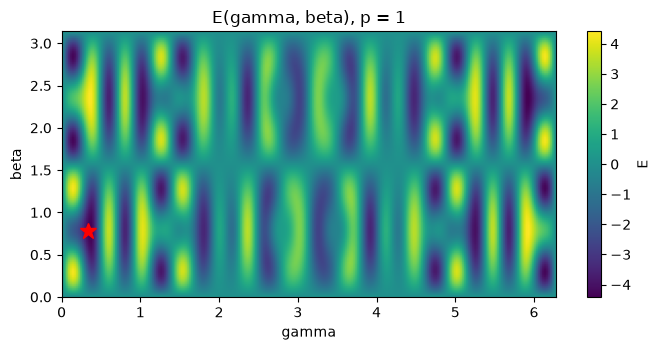

số điểm cực tiểu địa phương trên lưới (tính cả các bản sao do tính tuần hoàn và đối xứng): 44


In [2]:
gs = np.linspace(0, 2*np.pi, 241)
bs = np.linspace(0, np.pi, 121)
E = np.array([[qaoa_expectation(cost, [g], [b]) for g in gs] for b in bs])
i, j = np.unravel_index(E.argmin(), E.shape)
print(f"cực tiểu trên lưới: E = {E[i, j]:.3f} tại gamma = {gs[j]:.3f}, beta = {bs[i]:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(E, origin="lower", aspect="auto", extent=[gs[0], gs[-1], bs[0], bs[-1]], cmap="viridis")
ax.plot(gs[j], bs[i], "r*", ms=12)
ax.set_xlabel("gamma"); ax.set_ylabel("beta"); ax.set_title("E(gamma, beta), p = 1")
fig.colorbar(im, ax=ax, label="E"); plt.tight_layout(); plt.show()
print("số điểm cực tiểu địa phương trên lưới (tính cả các bản sao do tính tuần hoàn và đối xứng):",
      int(sum(E[a, b] < min(E[a-1, b], E[a+1, b], E[a, b-1], E[a, b+1])
              for a in range(1, E.shape[0]-1) for b in range(1, E.shape[1]-1))))

Cảnh quan có nhiều "thung lũng" tách biệt, nên bộ tối ưu cổ điển (COBYLA, BFGS, ...) phụ thuộc điểm khởi đầu. Đây là khó khăn cốt lõi của các thuật toán biến phân, thường gọi là vấn đề *tối ưu tham số*.

## 2. Độ sâu $p$ và chất lượng nghiệm

Với mỗi $p$, ta chạy BFGS từ nhiều điểm khởi đầu ngẫu nhiên rồi lấy kết quả tốt nhất. Cột `P(tối ưu)` là xác suất đo được $|000\rangle$.

In [3]:
rng = np.random.default_rng(0)
def best_over_starts(p, starts=12):
    best_val, best_x = np.inf, None
    for _ in range(starts):
        x0 = np.concatenate([rng.uniform(0, 1.5, p), rng.uniform(0, np.pi/2, p)])
        r = minimize(lambda t: qaoa_expectation(cost, t[:p], t[p:]), x0, method="BFGS")
        if r.fun < best_val:
            best_val, best_x = r.fun, r.x
    return best_val, best_x

table = []
for p in range(1, 7):
    v, x = best_over_starts(p)
    prob = np.abs(qaoa_state(cost, x[:p], x[p:])) ** 2
    table.append((p, v, prob[0]))
print(" p   E tốt nhất   P(tối ưu)")
for p, v, pr in table:
    print(f" {p}    {v:8.3f}     {pr:6.3f}")
print("tham chiếu: E tối ưu = -9, chọn ngẫu nhiên: E = 0 và P = 0.125")

 p   E tốt nhất   P(tối ưu)
 1      -4.432      0.492
 2      -6.986      0.629
 3      -8.540      0.955
 4      -8.774      0.972
 5      -8.942      0.993
 6      -9.000      1.000
tham chiếu: E tối ưu = -9, chọn ngẫu nhiên: E = 0 và P = 0.125


Chất lượng tăng nhanh theo $p$; ở bài 3 qubit này, $p = 5$–$6$ đã gần như chắc chắn cho nghiệm tối ưu. Lưu ý đây là bài rất nhỏ và là mô phỏng không nhiễu. Trên máy thật, mỗi lớp thêm vào làm mạch sâu hơn nên nhiễu tăng, như đã thấy ở [Notebook C2](../C-hardware/02-ibm-quantum-qaoa.ipynb).

## 3. QAOA là phiên bản "rời rạc hóa" của quá trình ủ

Nếu lấy $\gamma_k = s_k\,\Delta t$ và $\beta_k = -(1-s_k)\,\Delta t$ với $s_k = (k + \tfrac12)/p$ và $\Delta t = T/p$, thì QAOA độ sâu $p$ chính là xấp xỉ Trotter của quá trình ủ có thời gian $T$ ở [Notebook B1](01-hamiltonian-and-annealing.ipynb). Khi $p \to \infty$ với $T$ cố định, hai kết quả phải trùng nhau.

In [4]:
from scipy.linalg import eigh
X = np.array([[0.0, 1.0], [1.0, 0.0]]); I2 = np.eye(2)
def on(ops):
    out = np.array([[1.0]])
    for m in reversed(ops): out = np.kron(out, m)
    return out
H0 = -sum(on([X if j == q else I2 for j in range(3)]) for q in range(3)); HP = np.diag(cost)

def anneal_E(T, N=4000):
    dt = T / N; psi = np.ones(8, complex) / np.sqrt(8)
    for step in range(N):
        s = (step + 0.5) / N
        w, V = eigh((1 - s) * H0 + s * HP)
        psi = V @ (np.exp(-1j * w * dt) * (V.conj().T @ psi))
    return float(np.abs(psi) ** 2 @ cost)

for T in (4, 8):
    ref = anneal_E(T)
    print(f"T = {T}: ủ liên tục E = {ref:.3f}")
    for p in (4, 8, 16, 32, 64, 128):
        dt = T / p; sk = (np.arange(p) + 0.5) / p
        e = qaoa_expectation(cost, sk * dt, -(1 - sk) * dt)
        print(f"    QAOA p = {p:3d} với tham số 'ủ':  E = {e:7.3f}")

T = 4: ủ liên tục E = -6.860
    QAOA p =   4 với tham số 'ủ':  E =   2.209
    QAOA p =   8 với tham số 'ủ':  E =  -6.115
    QAOA p =  16 với tham số 'ủ':  E =  -6.930
    QAOA p =  32 với tham số 'ủ':  E =  -6.916
    QAOA p =  64 với tham số 'ủ':  E =  -6.893
    QAOA p = 128 với tham số 'ủ':  E =  -6.878
T = 8: ủ liên tục E = -8.416
    QAOA p =   4 với tham số 'ủ':  E =   2.173
    QAOA p =   8 với tham số 'ủ':  E =  -0.458
    QAOA p =  16 với tham số 'ủ':  E =  -7.490
    QAOA p =  32 với tham số 'ủ':  E =  -8.428
    QAOA p =  64 với tham số 'ủ':  E =  -8.433
    QAOA p = 128 với tham số 'ủ':  E =  -8.427


Với $p$ lớn, kết quả hội tụ về giá trị của quá trình ủ liên tục (các dao động nhỏ quanh giá trị đó là sai số Trotter). Còn khi **tối ưu tự do** các tham số (Mục 2), ở lần chạy này $p = 3$ đã đạt $E \approx -8{,}5$ và $p = 4$ đạt $E \approx -8{,}8$, tốt hơn quá trình ủ có $T = 8$ ($E \approx -8{,}4$) với độ sâu mạch nhỏ hơn nhiều so với $p = 32$ cần để QAOA "bắt chước" quá trình ủ đó. Đây là lý do QAOA hấp dẫn, nhưng cái giá là phải tối ưu $2p$ tham số bằng vòng lặp cổ điển (xem [B-07](../../docs/B-extensions/07-benchmarking.md)). Cần nhớ đây chỉ là một bài 3 qubit.